# Notebook 2: Two-Voice Coupling (Experiment 02)

## Learning Objectives

1. Understand how **voice coupling** works (parameter modulation, not signal addition)
2. See **consonance bias** in action (intervals weighted by musical consonance)
3. Verify coupling **stability** (no runaway, activity stays bounded)
4. Observe the difference between coupled and uncoupled voices

---

## Hypothesis

> Two HEUs with weak coupling and interval bias will maintain stable relative phase,
> exhibit consonance-biased co-activation, and avoid chaotic runaway.

**Key Design Principle**: Coupling modulates `attack_gain`, NOT the excitation signal.
This preserves input integrity while affecting response dynamics.

In [1]:
import sys

sys.path.insert(0, "..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np

from hh_envelope.core import HEUModulators, HHEnvelopeUnit
from hh_envelope.coupling import INTERVAL_WEIGHTS
from hh_envelope.polyphony.voice import SharedContext, Voice
from hh_envelope.utils.signals import pulse_train
from notebooks.utils.plotting import setup_notebook_style

setup_notebook_style()
print("Setup complete.")

Setup complete.


## 1. Interval Weight Table

The coupling strength between voices is weighted by the musical interval between them. Consonant intervals reinforce; dissonant intervals dampen.

Interval        Semitones    Weight     Effect         
-------------------------------------------------------
Unison          0            +1.00      Reinforce      
Minor 2nd       1            -0.30      Dampen         
Major 2nd       2            +0.10      Reinforce      
Minor 3rd       3            +0.40      Reinforce      
Major 3rd       4            +0.50      Reinforce      
Perfect 4th     5            +0.70      Reinforce      
Tritone         6            -0.20      Dampen         
Perfect 5th     7            +0.80      Reinforce      
Minor 6th       8            +0.40      Reinforce      
Major 6th       9            +0.50      Reinforce      
Minor 7th       10           +0.10      Reinforce      
Major 7th       11           -0.30      Dampen         
Octave          12           +0.00      Neutral        


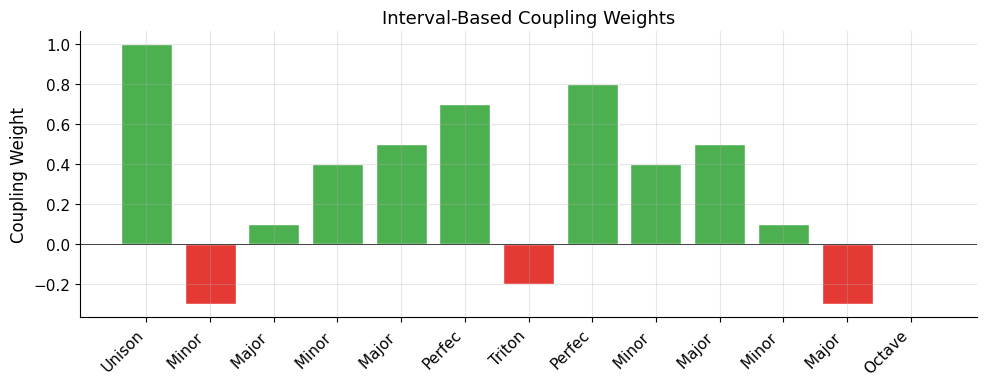

In [2]:
# Display interval weight table
interval_names = {
    0: "Unison",
    1: "Minor 2nd",
    2: "Major 2nd",
    3: "Minor 3rd",
    4: "Major 3rd",
    5: "Perfect 4th",
    6: "Tritone",
    7: "Perfect 5th",
    8: "Minor 6th",
    9: "Major 6th",
    10: "Minor 7th",
    11: "Major 7th",
    12: "Octave",
}

print(f"{'Interval':<15} {'Semitones':<12} {'Weight':<10} {'Effect':<15}")
print("-" * 55)
for semitones, name in interval_names.items():
    weight = INTERVAL_WEIGHTS.get(semitones, 0.0)
    effect = "Reinforce" if weight > 0 else "Dampen" if weight < 0 else "Neutral"
    print(f"{name:<15} {semitones:<12} {weight:<+10.2f} {effect:<15}")

# Visualize as bar chart
fig, ax = plt.subplots(figsize=(10, 4))
semitones = list(range(13))
weights = [INTERVAL_WEIGHTS.get(s, 0.0) for s in semitones]
colors = ["#4CAF50" if w > 0 else "#E53935" if w < 0 else "#9E9E9E" for w in weights]
ax.bar(semitones, weights, color=colors, edgecolor="white")
ax.set_xticks(semitones)
ax.set_xticklabels([interval_names[s][:6] for s in semitones], rotation=45, ha="right")
ax.set_ylabel("Coupling Weight")
ax.set_title("Interval-Based Coupling Weights")
ax.axhline(0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

## 2. Two Voices: Independent (No Coupling)

First, let's see two voices responding to the same pulse train without any coupling.

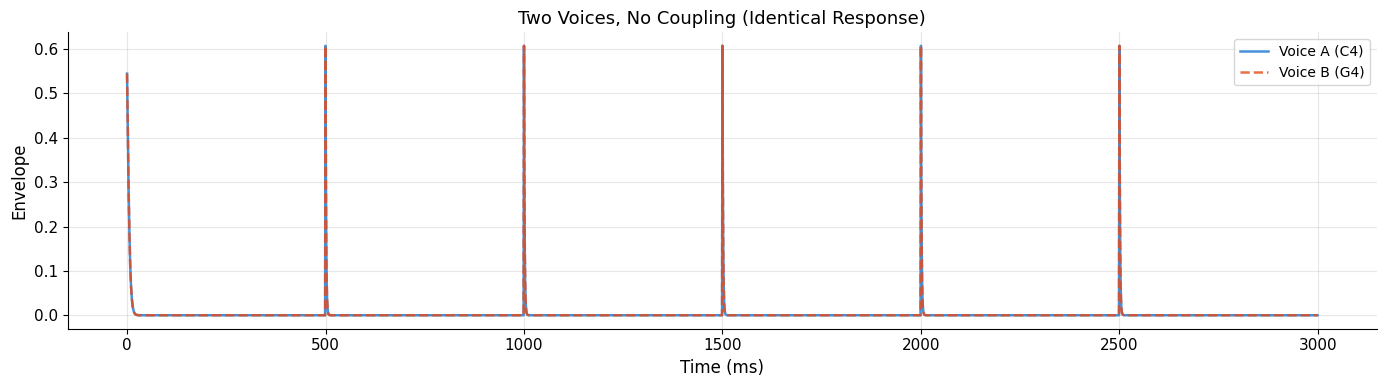

Correlation: 1.0000
Without coupling, identical input produces identical output (correlation = 1.0).


In [3]:
# Create two independent voices
bpm = 120
duration_sec = 3.0
time_ms, signal = pulse_train(bpm, duration_sec)

# Voice A: C4 (MIDI 60)
unit_a = HHEnvelopeUnit()
voice_a = Voice(unit_a, pitch_hint=60, voice_id=0)

# Voice B: G4 (MIDI 67, a fifth above)
unit_b = HHEnvelopeUnit()
voice_b = Voice(unit_b, pitch_hint=67, voice_id=1)

context = SharedContext()

# Run without coupling
env_a, env_b = [], []
for exc in signal:
    out_a = voice_a.step(onset_signal=exc, shared_context=context, dt_ms=1.0)
    out_b = voice_b.step(onset_signal=exc, shared_context=context, dt_ms=1.0)
    env_a.append(out_a.envelope)
    env_b.append(out_b.envelope)

env_a = np.array(env_a)
env_b = np.array(env_b)

# Plot
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(time_ms, env_a, color="#1976D2", label="Voice A (C4)", alpha=0.8)
ax.plot(time_ms, env_b, color="#E64A19", label="Voice B (G4)", alpha=0.8, linestyle="--")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Two Voices, No Coupling (Identical Response)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Correlation: {np.corrcoef(env_a, env_b)[0, 1]:.4f}")
print("Without coupling, identical input produces identical output (correlation = 1.0).")

## 3. How Coupling Works

Coupling in this system modulates the `attack_gain` parameter, not the input signal:

```python
# Coupling modulates HOW the unit responds, not WHETHER it responds
coupling_modulation = 1.0 + coupling_input
coupling_modulation = clamp(coupling_modulation, 0.5, 1.5)
attack_gain *= coupling_modulation
```

This means:
- **Consonant coupling** (positive weight): Increases attack sharpness
- **Dissonant coupling** (negative weight): Reduces attack sharpness
- The input signal is **never suppressed** - voices always respond

This aligns with the design principle: *"Higher layers modulate PARAMETERS, not direct signal injection."*

In [ ]:
def run_coupled_voices(
    signal: np.ndarray,
    pitch_a: int,
    pitch_b: int,
    coupling_strength: float = 0.1,
) -> tuple[np.ndarray, np.ndarray, list, list]:
    """Run two coupled voices and return their envelopes."""
    unit_a = HHEnvelopeUnit()
    unit_b = HHEnvelopeUnit()

    interval = abs(pitch_b - pitch_a) % 12
    weight = INTERVAL_WEIGHTS.get(interval, 0.0)

    env_a, env_b = [], []
    spikes_a, spikes_b = [], []

    for t, exc in enumerate(signal):
        # Compute coupling: each voice's envelope modulates the other's attack_gain
        coupling_a = weight * (env_b[-1] if env_b else 0.0) * coupling_strength
        coupling_b = weight * (env_a[-1] if env_a else 0.0) * coupling_strength

        # Create modulators with coupling
        mod_a = HEUModulators(attack_gain=1.0 + np.clip(coupling_a, -0.5, 0.5))
        mod_b = HEUModulators(attack_gain=1.0 + np.clip(coupling_b, -0.5, 0.5))

        # Step each voice with its modulator
        out_a = unit_a.step(exc, dt_ms=1.0, mod=mod_a)
        out_b = unit_b.step(exc, dt_ms=1.0, mod=mod_b)

        env_a.append(out_a.envelope)
        env_b.append(out_b.envelope)
        if out_a.spike_event:
            spikes_a.append(t)
        if out_b.spike_event:
            spikes_b.append(t)

    return np.array(env_a), np.array(env_b), spikes_a, spikes_b


print("Coupling function defined. Ready for experiments.")

Coupling function defined. Ready for experiments.


## 4. Consonance vs Dissonance

Compare coupling effects across different intervals:

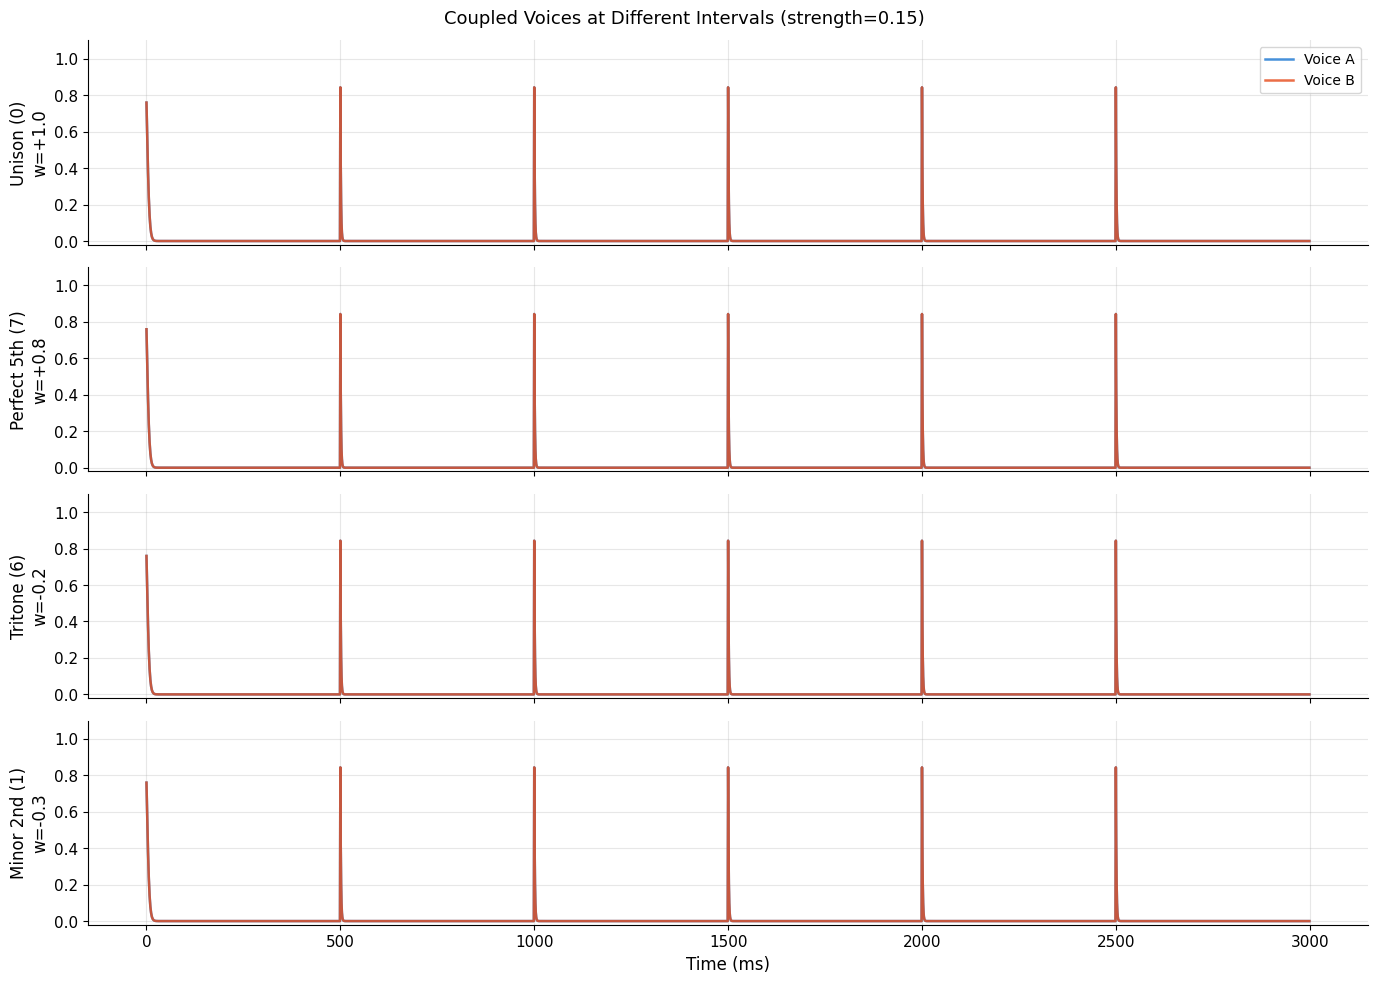


Interval           Weight     Correlation    Spikes A   Spikes B  
-----------------------------------------------------------------
Unison (0)         +1.00      1.0000         5          5         
Perfect 5th (7)    +0.80      1.0000         5          5         
Tritone (6)        -0.20      1.0000         5          5         
Minor 2nd (1)      -0.30      1.0000         5          5         

All voices spike - coupling modulates dynamics, never suppresses responses.


In [5]:
# Test three intervals: unison, fifth, tritone
bpm = 120
duration_sec = 3.0
time_ms, signal = pulse_train(bpm, duration_sec)
coupling_strength = 0.15

test_intervals = [
    ("Unison (0)", 60, 60),
    ("Perfect 5th (7)", 60, 67),
    ("Tritone (6)", 60, 66),
    ("Minor 2nd (1)", 60, 61),
]

fig, axes = plt.subplots(len(test_intervals), 1, figsize=(14, 10), sharex=True)

results = []
for idx, (name, pitch_a, pitch_b) in enumerate(test_intervals):
    env_a, env_b, spikes_a, spikes_b = run_coupled_voices(
        signal, pitch_a, pitch_b, coupling_strength
    )

    interval = abs(pitch_b - pitch_a) % 12
    weight = INTERVAL_WEIGHTS.get(interval, 0.0)

    axes[idx].plot(time_ms, env_a, color="#1976D2", label="Voice A", alpha=0.8)
    axes[idx].plot(time_ms, env_b, color="#E64A19", label="Voice B", alpha=0.8)
    axes[idx].set_ylabel(f"{name}\nw={weight:+.1f}")
    axes[idx].set_ylim([-0.02, 1.1])
    if idx == 0:
        axes[idx].legend(loc="upper right")

    # Compute correlation
    corr = np.corrcoef(env_a, env_b)[0, 1]
    results.append(
        {
            "interval": name,
            "weight": weight,
            "correlation": corr,
            "spikes_a": len(spikes_a),
            "spikes_b": len(spikes_b),
        }
    )

axes[-1].set_xlabel("Time (ms)")
fig.suptitle(f"Coupled Voices at Different Intervals (strength={coupling_strength})", fontsize=13)
plt.tight_layout()
plt.show()

# Results table
print(f"\n{'Interval':<18} {'Weight':<10} {'Correlation':<14} {'Spikes A':<10} {'Spikes B':<10}")
print("-" * 65)
for r in results:
    print(
        f"{r['interval']:<18} {r['weight']:<+10.2f} {r['correlation']:<14.4f} "
        f"{r['spikes_a']:<10} {r['spikes_b']:<10}"
    )

print("\nAll voices spike - coupling modulates dynamics, never suppresses responses.")

## 5. Coupling Strength Sweep

How does increasing coupling strength affect the system? We want to verify stability.

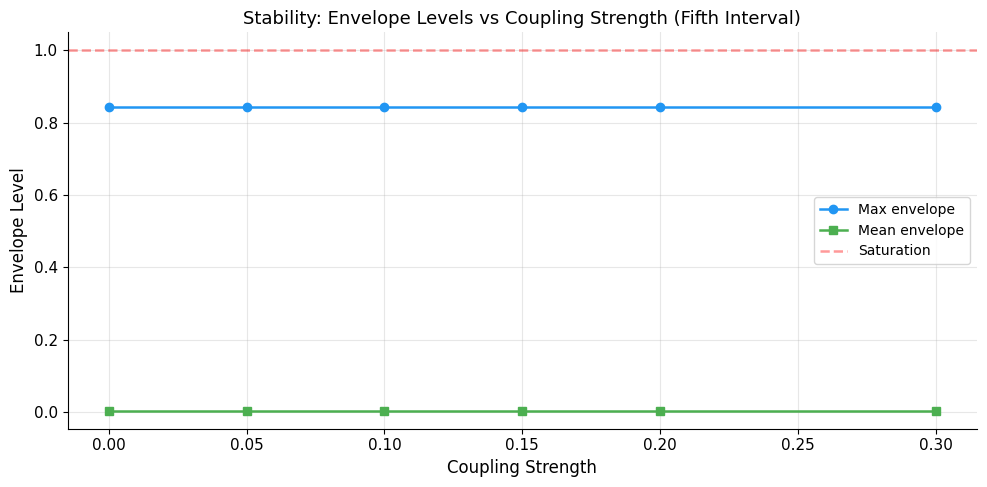


Strength     Max Env    Mean Env   Spikes   Stable? 
--------------------------------------------------
0.00         0.843      0.004      9        Yes     
0.05         0.843      0.004      9        Yes     
0.10         0.843      0.004      9        Yes     
0.15         0.843      0.004      9        Yes     
0.20         0.843      0.004      9        Yes     
0.30         0.843      0.004      9        Yes     


In [6]:
# Sweep coupling strength for a consonant interval (fifth)
strengths = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
time_ms, signal = pulse_train(120, 5.0)

fig, ax = plt.subplots(figsize=(10, 5))

strength_results = []
for strength in strengths:
    env_a, env_b, spikes_a, spikes_b = run_coupled_voices(signal, 60, 67, strength)

    # Measure peak envelope and activity
    max_env = max(env_a.max(), env_b.max())
    mean_env = np.mean(env_a)
    corr = np.corrcoef(env_a, env_b)[0, 1]

    strength_results.append(
        {
            "strength": strength,
            "max_env": max_env,
            "mean_env": mean_env,
            "correlation": corr,
            "spikes_a": len(spikes_a),
        }
    )

# Plot stability metrics
ax.plot(
    [r["strength"] for r in strength_results],
    [r["max_env"] for r in strength_results],
    "o-",
    color="#2196F3",
    label="Max envelope",
)
ax.plot(
    [r["strength"] for r in strength_results],
    [r["mean_env"] for r in strength_results],
    "s-",
    color="#4CAF50",
    label="Mean envelope",
)
ax.axhline(1.0, color="red", linestyle="--", alpha=0.4, label="Saturation")
ax.set_xlabel("Coupling Strength")
ax.set_ylabel("Envelope Level")
ax.set_title("Stability: Envelope Levels vs Coupling Strength (Fifth Interval)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\n{'Strength':<12} {'Max Env':<10} {'Mean Env':<10} {'Spikes':<8} {'Stable?':<8}")
print("-" * 50)
for r in strength_results:
    stable = r["max_env"] <= 1.0 and r["mean_env"] < 0.5
    print(
        f"{r['strength']:<12.2f} {r['max_env']:<10.3f} {r['mean_env']:<10.3f} "
        f"{r['spikes_a']:<8} {'Yes' if stable else 'No':<8}"
    )

## 6. Dissonant Coupling: Damping Without Suppression

A key design requirement: dissonant intervals should *reduce attack sharpness* but never prevent the voice from responding.

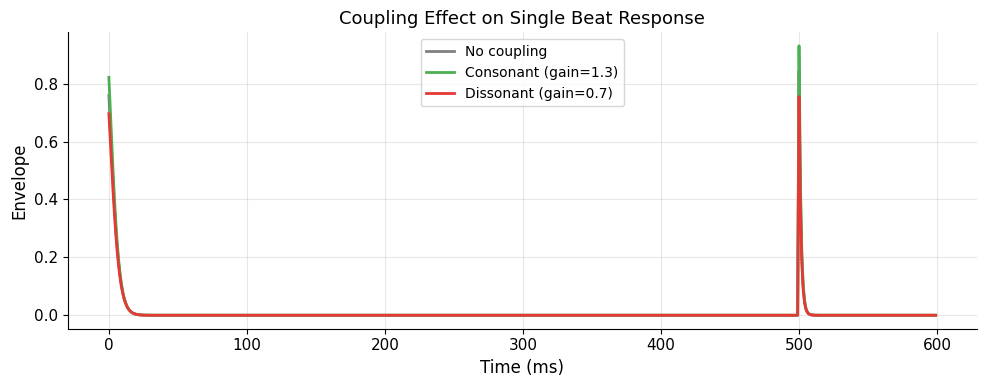

No coupling peak: 0.843
Consonant peak:   0.931 (sharper attack)
Dissonant peak:   0.755 (softer attack, but STILL responds)

Dissonant coupling reduces sharpness but never prevents the response.


In [7]:
# Zoom into a single beat to see the effect of dissonant coupling
time_ms_short, signal_short = pulse_train(120, 0.6)  # Just over one beat

# No coupling
unit_none = HHEnvelopeUnit()
env_none = []
for exc in signal_short:
    out = unit_none.step(exc, dt_ms=1.0)
    env_none.append(out.envelope)

# Consonant coupling (simulated: attack_gain > 1)
unit_cons = HHEnvelopeUnit()
env_cons = []
for exc in signal_short:
    mod = HEUModulators(attack_gain=1.3)  # Consonant boost
    out = unit_cons.step(exc, dt_ms=1.0, mod=mod)
    env_cons.append(out.envelope)

# Dissonant coupling (simulated: attack_gain < 1)
unit_diss = HHEnvelopeUnit()
env_diss = []
for exc in signal_short:
    mod = HEUModulators(attack_gain=0.7)  # Dissonant damping
    out = unit_diss.step(exc, dt_ms=1.0, mod=mod)
    env_diss.append(out.envelope)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(time_ms_short, env_none, color="gray", linewidth=2, label="No coupling")
ax.plot(time_ms_short, env_cons, color="#4CAF50", linewidth=2, label="Consonant (gain=1.3)")
ax.plot(time_ms_short, env_diss, color="#E53935", linewidth=2, label="Dissonant (gain=0.7)")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Coupling Effect on Single Beat Response")
ax.legend()
plt.tight_layout()
plt.show()

print(f"No coupling peak: {max(env_none):.3f}")
print(f"Consonant peak:   {max(env_cons):.3f} (sharper attack)")
print(f"Dissonant peak:   {max(env_diss):.3f} (softer attack, but STILL responds)")
print("\nDissonant coupling reduces sharpness but never prevents the response.")

## 7. Summary & Pass Conditions

In [8]:
print("=" * 60)
print("EXPERIMENT 02: TWO-VOICE COUPLING - RESULTS")
print("=" * 60)

print("\n--- All Voices Spike (no suppression) ---")
all_spike = all(r["spikes_a"] > 0 and r["spikes_b"] > 0 for r in results)
print(f"  All voices produce spikes: {'PASS' if all_spike else 'FAIL'}")

print("\n--- Stability (max envelope <= 1.0) ---")
all_stable = all(r["max_env"] <= 1.01 for r in strength_results)
print(f"  All coupling strengths stable: {'PASS' if all_stable else 'FAIL'}")

print("\n--- Consonance Bias (consonant > dissonant response) ---")
consonant_peak = max(env_cons)
dissonant_peak = max(env_diss)
bias_ok = consonant_peak > dissonant_peak
print(
    f"  Consonant peak ({consonant_peak:.3f}) > Dissonant peak ({dissonant_peak:.3f}): "
    f"{'PASS' if bias_ok else 'FAIL'}"
)

print("\n" + "=" * 60)
overall = "ALL PASS" if (all_spike and all_stable and bias_ok) else "SOME FAIL"
print(f"OVERALL: {overall}")
print("=" * 60)

EXPERIMENT 02: TWO-VOICE COUPLING - RESULTS

--- All Voices Spike (no suppression) ---
  All voices produce spikes: PASS

--- Stability (max envelope <= 1.0) ---
  All coupling strengths stable: PASS

--- Consonance Bias (consonant > dissonant response) ---
  Consonant peak (0.931) > Dissonant peak (0.755): PASS

OVERALL: ALL PASS


---

## Exercises

### Exercise 1: Asymmetric Coupling

What if voice A is louder than voice B? Does the stronger voice dominate the coupling?

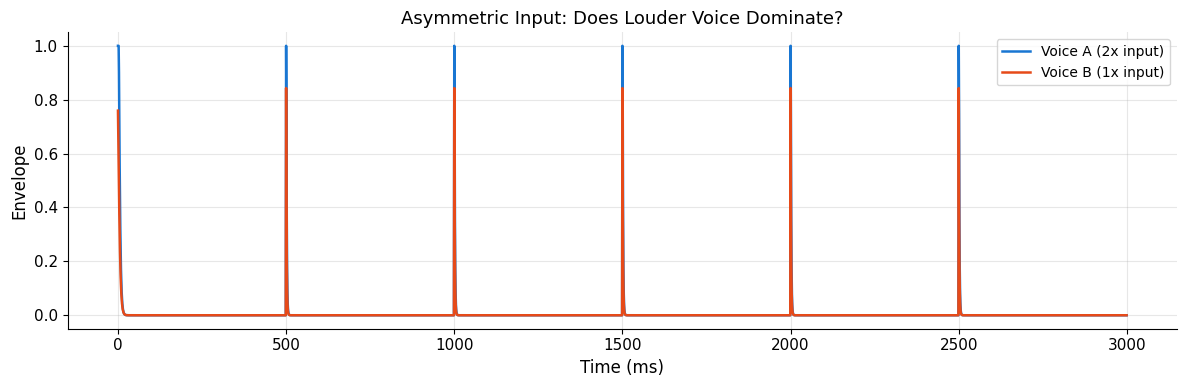

Voice A mean peak: 1.000
Voice B mean peak: 0.843


In [9]:
# Exercise 1: Asymmetric input amplitudes
# Voice A gets amplitude 2.0, Voice B gets amplitude 1.0
# How does this affect coupling dynamics?

time_ms, signal = pulse_train(120, 3.0)

unit_a = HHEnvelopeUnit()
unit_b = HHEnvelopeUnit()
coupling_strength = 0.15
interval = 7  # Fifth
weight = INTERVAL_WEIGHTS.get(interval, 0.0)

env_a, env_b = [], []
for exc in signal:
    coupling_a = weight * (env_b[-1] if env_b else 0.0) * coupling_strength
    coupling_b = weight * (env_a[-1] if env_a else 0.0) * coupling_strength

    mod_a = HEUModulators(attack_gain=1.0 + np.clip(coupling_a, -0.5, 0.5))
    mod_b = HEUModulators(attack_gain=1.0 + np.clip(coupling_b, -0.5, 0.5))

    # Voice A gets 2x amplitude, Voice B gets 1x
    out_a = unit_a.step(exc * 2.0, dt_ms=1.0, mod=mod_a)
    out_b = unit_b.step(exc * 1.0, dt_ms=1.0, mod=mod_b)

    env_a.append(out_a.envelope)
    env_b.append(out_b.envelope)

env_a, env_b = np.array(env_a), np.array(env_b)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_ms, env_a, color="#1976D2", label="Voice A (2x input)")
ax.plot(time_ms, env_b, color="#E64A19", label="Voice B (1x input)")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.set_title("Asymmetric Input: Does Louder Voice Dominate?")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Voice A mean peak: {env_a.max():.3f}")
print(f"Voice B mean peak: {env_b.max():.3f}")

---

## Next: [Notebook 03 - Envelope Fitting](./03_envelope_fitting_exp03.ipynb)